# ITRI625 Project: Phishing Email Detection with a BiLSTM

**Goal:** classify an email (subject + body) as **phishing/malicious (1)** or **legitimate (0)**, then serve the model through a FastAPI endpoint and a Tkinter desktop app.

| Rubric item | Where in this notebook |
|---|---|
| 2.1 Model development | Sections 3–9 (preprocessing, TF-IDF baseline, BiLSTM) |
| 2.2 Train / validation / test split | Section 6 |
| 2.3 Metric logging after every epoch | Section 9 (`metrics_log`, also saved to `results/metrics_log.csv`) |
| 2.4 Metric graphs (Matplotlib) | Sections 5, 10 |
| 2.5 API + desktop app | Section 11 saves the model; see `api/main.py` and `app/desktop_app.py` |
| 2.6 Patience / early stopping | Section 9 (`EarlyStopping` class) |
| 2.7 Additional features | Section 13 (XAI: LR coefficients, occlusion, LIME), threshold tuning, baseline comparison, Docker hosting |

> **Shared code.** The text-cleaning and model code is written in this notebook with `%%writefile` cells (Sections 3 and 8). The cells write it into `phishing_core/` so the API loads the **exact same** code. Edit the code here, not in the `.py` files.

## 1. Setup

In [ ]:
import sys, time, random, json, importlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             log_loss)
import joblib

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Paths work on Windows/Mac/Linux as long as the notebook is run from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, MODEL_DIR = ROOT / "data", ROOT / "models"
RESULTS_DIR, FIG_DIR = ROOT / "results", ROOT / "results" / "figures"
for d in (MODEL_DIR, RESULTS_DIR, FIG_DIR, ROOT / "phishing_core"):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__}")
print("Project root:", ROOT)
print("Device:", DEVICE)

## 2. Load the data

All `*.csv` files in `data/` are loaded and stacked. The project currently uses **CEAS_08.csv** from the Kaggle *Phishing Email Dataset* collection. You can add **Nazario.csv** (real phishing) and **Nigerian_Fraud.csv** from the same collection into `data/` and re-run. They have the same columns and are picked up automatically.

Label convention: `1` = phishing/malicious, `0` = legitimate.

In [ ]:
def load_dataset(data_dir, files=None):
    """Load and standardise every CSV into columns: source, subject, body, label."""
    paths = [data_dir / f for f in files] if files else sorted(data_dir.glob("*.csv"))
    frames = []
    for p in paths:
        df = pd.read_csv(p)
        cols = {c.lower(): c for c in df.columns}
        if "body" not in cols and "text_combined" in cols:      # alternative file format
            df = df.rename(columns={cols["text_combined"]: "body"}); cols["body"] = "body"
        if "body" not in cols or "label" not in cols:
            print(f"  skipping {p.name}: needs 'body' and 'label' columns"); continue
        out = pd.DataFrame({
            "source": p.stem,
            "subject": df[cols["subject"]] if "subject" in cols else "",
            "body": df[cols["body"]],
            "label": pd.to_numeric(df[cols["label"]], errors="coerce"),
        })
        frames.append(out)
        print(f"  {p.name:<28} {len(out):>7,} rows")
    data = pd.concat(frames, ignore_index=True).dropna(subset=["label"])
    data["label"] = data["label"].astype(int)
    return data

DATA_FILES = None          # None = every CSV in data/. Or e.g. ["CEAS_08.csv", "Nazario.csv"]
raw = load_dataset(DATA_DIR, DATA_FILES)
print(f"\nTotal: {len(raw):,} emails")
display(raw.groupby("source")["label"].value_counts().unstack().rename(columns={0: "legitimate", 1: "phishing"}))
raw.head()

## 3. Text preprocessing (shared with the API)

Each email is cleaned in the same way during training and inside the API:

1. Join the **subject and body** into one string, decode HTML entities and strip HTML tags.
2. Replace URLs with `urltoken`, e-mail addresses with `emailtoken` and numbers with `numtoken`. The model then learns *that* an email contains a link, not the specific domain, which goes stale fast.
3. Lowercase the text and remove punctuation, but keep `! ? $ %` as their own tokens. Urgency and money symbols are strong phishing signals.
4. Tokenise on whitespace. The vocabulary is built **from the training set only**, keeping the 25,000 most frequent words that occur at least twice. Unknown words map to `<unk>`.

In [ ]:
%%writefile ../phishing_core/__init__.py
"""Shared code for the phishing email detector (written out by notebooks/02_model_training.ipynb)."""

In [ ]:
%%writefile ../phishing_core/text.py
"""Text cleaning, tokenisation and vocabulary for the phishing email detector.

This file is generated from notebooks/02_model_training.ipynb (%%writefile cell).
Edit it there and re-run the notebook so the notebook and the API stay in sync.
"""
import html
import json
import re
from collections import Counter
from pathlib import Path

URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
HTML_TAG_RE = re.compile(r"<[^>]+>")
NUM_RE = re.compile(r"\b\d+(?:[.,]\d+)*\b")
NON_WORD_RE = re.compile(r"[^a-z0-9$!?%\s]")
SPACE_RE = re.compile(r"\s+")

PAD, UNK = "<pad>", "<unk>"


def clean_text(subject, body) -> str:
    """Combine subject + body and normalise them into a single lowercase string.

    URLs, e-mail addresses and numbers are replaced with placeholder tokens so the
    model learns *that* a link is present rather than memorising specific domains.
    """
    subject = "" if subject is None or subject != subject else str(subject)  # handles NaN
    body = "" if body is None or body != body else str(body)
    text = f"{subject} {body}"
    text = html.unescape(text)
    text = HTML_TAG_RE.sub(" ", text)
    text = URL_RE.sub(" urltoken ", text)
    text = EMAIL_RE.sub(" emailtoken ", text)
    text = text.lower()
    text = NUM_RE.sub(" numtoken ", text)
    text = NON_WORD_RE.sub(" ", text)
    # keep ! ? $ % as separate tokens - they are strong spam/phishing signals
    text = re.sub(r"([$!?%])", r" \1 ", text)
    return SPACE_RE.sub(" ", text).strip()


def tokenize(text: str) -> list:
    return text.split()


def count_urls(text) -> int:
    return len(URL_RE.findall(str(text or "")))


class Vocab:
    """Word -> integer index mapping, built on the TRAINING set only (no leakage)."""

    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    @classmethod
    def build(cls, token_lists, max_size=25000, min_freq=2):
        counts = Counter(t for toks in token_lists for t in toks)
        words = [w for w, c in counts.most_common() if c >= min_freq][: max_size - 2]
        return cls([PAD, UNK] + words)

    def __len__(self):
        return len(self.itos)

    @property
    def pad_idx(self):
        return 0

    @property
    def unk_idx(self):
        return 1

    def encode(self, tokens, max_len=300):
        ids = [self.stoi.get(t, 1) for t in tokens[:max_len]]
        return ids if ids else [1]  # never return an empty sequence

    def save(self, path):
        Path(path).write_text(json.dumps(self.itos), encoding="utf-8")

    @classmethod
    def load(cls, path):
        return cls(json.loads(Path(path).read_text(encoding="utf-8")))

In [ ]:
import phishing_core.text as ptext
importlib.reload(ptext)
from phishing_core.text import clean_text, tokenize, Vocab, count_urls

example = raw.iloc[0]
print("SUBJECT:", example.subject)
print("RAW BODY:", str(example.body)[:300], "...")
print("\nCLEANED:", clean_text(example.subject, example.body)[:300], "...")

## 4. Cleaning and de-duplication

Merged email corpora contain many **exact duplicates**: newsletters, mass spam campaigns and re-sent messages. If a duplicate lands in both train and test, the test score measures memorisation rather than generalisation. This is **data leakage**, so duplicates are removed *before* the split.

In [ ]:
t0 = time.time()
raw["text"] = [clean_text(s, b) for s, b in zip(raw["subject"], raw["body"])]
print(f"Cleaned {len(raw):,} emails in {time.time()-t0:.1f}s")

n0 = len(raw)
df = raw[raw["text"].str.len() > 0]
n_empty = n0 - len(df)
dup_mask = df.duplicated(subset="text", keep="first")
conflicting = df[dup_mask].merge(df[~dup_mask][["text", "label"]], on="text", suffixes=("", "_first"))
n_conflict = int((conflicting["label"] != conflicting["label_first"]).sum())
df = df[~dup_mask].reset_index(drop=True)
df["n_tokens"] = df["text"].str.split().str.len()
df["n_urls"] = [count_urls(f"{s} {b}") for s, b in zip(df["subject"], df["body"])]

summary = pd.DataFrame({
    "step": ["raw emails", "removed: empty after cleaning", "removed: exact duplicates",
             "  (of which duplicates with a different label)", "final unique emails"],
    "count": [n0, n_empty, int(dup_mask.sum()), n_conflict, len(df)],
})
display(summary)

## 5. Exploratory data analysis

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

counts = df["label"].value_counts().sort_index()
axes[0].bar(["Legitimate (0)", "Phishing (1)"], counts.values, color=["#2e7d32", "#c62828"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("Class balance (after de-duplication)"); axes[0].set_ylabel("emails")
axes[0].set_ylim(0, counts.max() * 1.2)

bins = np.logspace(0, np.log10(df["n_tokens"].max() + 1), 50)
for lab, name, col in [(0, "Legitimate", "#2e7d32"), (1, "Phishing", "#c62828")]:
    axes[1].hist(df.loc[df.label == lab, "n_tokens"], bins=bins, alpha=0.6, label=name, color=col)
axes[1].set_xscale("log"); axes[1].axvline(256, ls="--", c="k", lw=1, label="max_len = 256")
axes[1].set_title("Email length (tokens, log scale)"); axes[1].set_xlabel("tokens"); axes[1].legend()

url_tab = df.assign(urls=df["n_urls"].clip(upper=5)).groupby(["urls", "label"]).size().unstack(fill_value=0)
url_tab = url_tab / url_tab.sum()
url_tab.plot.bar(ax=axes[2], color=["#2e7d32", "#c62828"], rot=0)
axes[2].set_xticklabels([str(i) if i < 5 else "5+" for i in url_tab.index])
axes[2].set_title("URLs per email (share within each class)"); axes[2].set_xlabel("number of URLs")
axes[2].legend(["Legitimate", "Phishing"])
plt.tight_layout(); savefig("eda_overview"); plt.show()

print("Token length percentiles (50/75/90/95):", np.percentile(df["n_tokens"], [50, 75, 90, 95]).round())
print(f"Share of emails fully covered by max_len=256: {(df['n_tokens'] <= 256).mean():.1%}")

In [ ]:
from collections import Counter
STOP = set(ENGLISH_STOP_WORDS) | {"numtoken", "urltoken", "emailtoken", "!", "?", "$", "%"}

def top_words(texts, n=15):
    c = Counter(w for t in texts for w in set(t.split()) if w not in STOP and len(w) > 2)
    return c.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, name, col in [(axes[0], 0, "Legitimate", "#2e7d32"), (axes[1], 1, "Phishing", "#c62828")]:
    words, freq = zip(*top_words(df.loc[df.label == lab, "text"]))
    ax.barh(words[::-1], np.array(freq[::-1]) / (df.label == lab).sum(), color=col)
    ax.set_title(f"Most common words: {name}"); ax.set_xlabel("share of emails containing word")
plt.tight_layout(); savefig("eda_top_words"); plt.show()

## 6. Train / validation / test split (rubric 2.2)

Stratified **70 / 15 / 15** split with a fixed seed, so the class ratio matches in each set and the split can be reproduced.

* **Train:** fits the model weights and builds the vocabulary.
* **Validation:** checked after every epoch for early stopping, model selection and choosing the decision threshold.
* **Test:** used **once**, at the end, for the final reported results.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

split_summary = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "emails": [len(train_df), len(val_df), len(test_df)],
    "share": [len(train_df)/len(df), len(val_df)/len(df), len(test_df)/len(df)],
    "phishing": [d.label.sum() for d in (train_df, val_df, test_df)],
    "phishing_rate": [d.label.mean() for d in (train_df, val_df, test_df)],
})
display(split_summary.style.format({"share": "{:.1%}", "phishing_rate": "{:.1%}", "emails": "{:,}", "phishing": "{:,}"}))
assert not set(train_df.text) & set(test_df.text), "leakage: identical email in train and test"
assert not set(train_df.text) & set(val_df.text), "leakage: identical email in train and validation"
print("No identical emails shared between splits.")

## 7. Baseline: TF-IDF + Logistic Regression

A classical baseline sets a reference point, so we can show the deep model actually adds something. TF-IDF weights each word or two-word phrase by how distinctive it is. Logistic regression then learns one weight per feature. The baseline is fast, and the weights are directly interpretable (see Section 13).

In [ ]:
def compute_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
    }

def best_f1_threshold(y_true, prob):
    """Pick the decision threshold that maximises F1 on the VALIDATION set."""
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.argmax(f1[:-1])])

t0 = time.time()
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
    ("clf", LogisticRegression(C=4.0, max_iter=2000)),
])
baseline.fit(train_df.text, train_df.label)
print(f"Baseline trained in {time.time()-t0:.1f}s")

base_val_prob = baseline.predict_proba(val_df.text)[:, 1]
BASE_THRESHOLD = best_f1_threshold(val_df.label, base_val_prob)
base_test_prob = baseline.predict_proba(test_df.text)[:, 1]

display(pd.DataFrame({
    "validation": compute_metrics(val_df.label, base_val_prob, BASE_THRESHOLD),
    "test": compute_metrics(test_df.label, base_test_prob, BASE_THRESHOLD),
}).T.style.format("{:.4f}").set_caption(f"TF-IDF + LogReg (threshold {BASE_THRESHOLD:.3f}, tuned on validation)"))
joblib.dump(baseline, MODEL_DIR / "baseline_tfidf_logreg.joblib")

## 8. Main model: Bidirectional LSTM (rubric 2.1)

**Architecture** (the full code is in the cell below):

| Layer | Details | Output shape |
|---|---|---|
| Input | token ids, truncated to `max_len = 256` (covers ~80% of emails in full) | (B, T) |
| Embedding | 25,000 × 100, learned from scratch, `padding_idx = 0` | (B, T, 100) |
| Dropout | p = 0.3 | |
| BiLSTM | 1 layer, 64 hidden units per direction, packed sequences so padding is ignored | (B, T, 128) |
| Pooling | masked **mean** + masked **max** over time, concatenated | (B, 256) |
| Dense + ReLU | 256 → 64 | (B, 64) |
| Dropout | p = 0.3 | |
| Output | 64 → 1 logit; **sigmoid** gives P(phishing) | (B,) |

* **Loss:** `BCEWithLogitsLoss` (sigmoid + binary cross-entropy).
* **Optimiser:** Adam, learning rate 1e-3, gradient clipping at 1.0.
* **Why a BiLSTM suits email text:**
  * Word order and context matter ("verify your account" vs "account verified").
  * The forward and backward passes let each word see both what came before and what comes after.
  * Max-pooling captures the single most suspicious phrase anywhere in the email, while mean-pooling captures the overall tone.

In [ ]:
%%writefile ../phishing_core/model.py
"""BiLSTM phishing classifier + an inference wrapper used by the notebook and the API.

This file is generated from notebooks/02_model_training.ipynb (%%writefile cell).
Edit it there and re-run the notebook so the notebook and the API stay in sync.
"""
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .text import Vocab, clean_text, count_urls, tokenize


class BiLSTMClassifier(nn.Module):
    """Embedding -> BiLSTM -> masked mean+max pooling -> MLP head -> 1 logit.

    Output is a single logit; sigmoid(logit) = P(phishing). Trained with
    BCEWithLogitsLoss (sigmoid + binary cross-entropy in one numerically stable op).
    """

    def __init__(self, vocab_size, emb_dim=100, hidden_dim=64, num_layers=1,
                 dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 2 * 2, 64),  # (fwd+bwd) x (mean+max)
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x, lengths):
        emb = self.emb_dropout(self.embedding(x))                       # (B, T, E)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True,
                                     total_length=x.size(1))            # (B, T, 2H)
        mask = (torch.arange(x.size(1), device=x.device)[None, :]
                < lengths[:, None].to(x.device)).unsqueeze(-1)          # (B, T, 1)
        mean_pool = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        max_pool = out.masked_fill(~mask, -1e9).max(1).values
        return self.head(torch.cat([mean_pool, max_pool], dim=1)).squeeze(1)


def collate_ids(seqs, pad_idx=0):
    """Pad a list of id-lists into a batch tensor plus a lengths tensor."""
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)
    batch = torch.full((len(seqs), int(lengths.max())), pad_idx, dtype=torch.long)
    for i, s in enumerate(seqs):
        batch[i, : len(s)] = torch.tensor(s, dtype=torch.long)
    return batch, lengths


class PhishingDetector:
    """Loads the saved BiLSTM (and optional baseline) and serves predictions."""

    def __init__(self, model_dir):
        model_dir = Path(model_dir)
        self.config = json.loads((model_dir / "config.json").read_text(encoding="utf-8"))
        self.vocab = Vocab.load(model_dir / "vocab.json")
        self.max_len = self.config["max_len"]
        self.threshold = float(self.config.get("threshold", 0.5))
        self.device = torch.device("cpu")
        self.model = BiLSTMClassifier(len(self.vocab), **self.config["model_params"])
        state = torch.load(model_dir / "bilstm.pt", map_location=self.device)
        self.model.load_state_dict(state)
        self.model.eval()
        self.baseline = None
        baseline_path = model_dir / "baseline_tfidf_logreg.joblib"
        if baseline_path.exists():
            import joblib
            self.baseline = joblib.load(baseline_path)
            self.baseline_threshold = float(self.config.get("baseline_threshold", 0.5))

    # ---------- BiLSTM ----------
    @torch.no_grad()
    def _logits_from_tokens(self, token_lists, batch_size=256):
        logits = []
        for i in range(0, len(token_lists), batch_size):
            ids = [self.vocab.encode(t, self.max_len) for t in token_lists[i:i + batch_size]]
            x, lengths = collate_ids(ids)
            logits.append(self.model(x, lengths).numpy())
        return np.concatenate(logits) if logits else np.array([])

    def _proba_from_tokens(self, token_lists, batch_size=256):
        return 1.0 / (1.0 + np.exp(-self._logits_from_tokens(token_lists, batch_size)))

    def predict_proba(self, texts):
        """texts: list of already-cleaned strings -> P(phishing) for each."""
        return self._proba_from_tokens([tokenize(t) for t in texts])

    def explain(self, text, top_k=10):
        """Occlusion (leave-one-word-out) explanation.

        For each distinct word, remove every occurrence and measure how much the
        model's log-odds of phishing change. Log-odds are used instead of the raw
        probability because a probability of 0.9999 hardly moves when one word is
        removed (sigmoid saturation), while the log-odds still show the effect.
        Positive weight = the word pushes the email towards phishing.
        """
        tokens = tokenize(text)[: self.max_len]
        if not tokens:
            return []
        base = float(self._logits_from_tokens([tokens])[0])
        words = list(dict.fromkeys(tokens))[:200]
        variants = [[t for t in tokens if t != w] or ["<unk>"] for w in words]
        weights = base - self._logits_from_tokens(variants)
        order = np.argsort(-np.abs(weights))[:top_k]
        return [{"token": words[i], "weight": round(float(weights[i]), 4)} for i in order]

    # ---------- public API ----------
    def analyse(self, subject, body, model="bilstm", explain=True, top_k=10):
        text = clean_text(subject, body)
        if model == "baseline":
            if self.baseline is None:
                raise ValueError("Baseline model not available")
            prob = float(self.baseline.predict_proba([text])[0, 1])
            threshold = self.baseline_threshold
            tokens = self._baseline_explain(text, top_k) if explain else []
        else:
            prob = float(self.predict_proba([text])[0])
            threshold = self.threshold
            tokens = self.explain(text, top_k) if explain else []
        return {
            "label": "phishing" if prob >= threshold else "legitimate",
            "probability": round(prob, 4),
            "threshold": round(threshold, 4),
            "model": model,
            "top_tokens": tokens,
            "indicators": {
                "url_count": count_urls(f"{subject or ''} {body or ''}"),
                "word_count": len(tokenize(text)),
                "exclamation_marks": text.count("!"),
            },
        }

    def _baseline_explain(self, text, top_k=10):
        """For TF-IDF + LogReg: contribution = tfidf value x coefficient."""
        vec = self.baseline.named_steps["tfidf"]
        clf = self.baseline.named_steps["clf"]
        row = vec.transform([text]).tocoo()
        names = vec.get_feature_names_out()
        contrib = [(names[j], float(v * clf.coef_[0][j])) for j, v in zip(row.col, row.data)]
        contrib.sort(key=lambda t: -abs(t[1]))
        return [{"token": w, "weight": round(c, 4)} for w, c in contrib[:top_k]]

In [ ]:
import phishing_core.model as pmodel
importlib.reload(pmodel)
from phishing_core.model import BiLSTMClassifier, collate_ids, PhishingDetector

CONFIG = {
    "max_len": 256, "vocab_size": 25000, "min_freq": 2,
    "model_params": {"emb_dim": 100, "hidden_dim": 64, "num_layers": 1, "dropout": 0.3},
    "batch_size": 64, "lr": 1e-3, "max_epochs": 15, "patience": 3, "min_delta": 1e-4, "grad_clip": 1.0,
}

vocab = Vocab.build((t.split() for t in train_df.text), CONFIG["vocab_size"], CONFIG["min_freq"])
encode = lambda texts: [vocab.encode(t.split(), CONFIG["max_len"]) for t in texts]
X_train, X_val, X_test = encode(train_df.text), encode(val_df.text), encode(test_df.text)
y_train, y_val, y_test = (d.label.values.astype(np.float32) for d in (train_df, val_df, test_df))
unk_rate = np.mean([np.mean(np.array(s) == vocab.unk_idx) for s in X_val])
print(f"Vocabulary: {len(vocab):,} tokens | unknown-token rate on validation: {unk_rate:.1%}")

model = BiLSTMClassifier(len(vocab), **CONFIG["model_params"]).to(DEVICE)
print(model)
layer_params = pd.DataFrame([(n, tuple(p.shape), p.numel()) for n, p in model.named_parameters()],
                            columns=["parameter", "shape", "count"])
display(layer_params)
print(f"Total trainable parameters: {layer_params['count'].sum():,}")

## 9. Training loop with per-epoch metric logging (2.3) and early stopping (2.6)

* **Length bucketing:** emails of similar length are batched together, so little time is wasted on padding. This keeps CPU training practical.
* **Per-epoch logging:** after **every epoch** we log train loss and accuracy, plus validation loss, accuracy, precision, recall, F1, AUC-ROC and PR-AUC. Each epoch's values are printed and stored in `metrics_log`, which is saved to CSV.
* **Early stopping:** if validation loss does not improve by at least `min_delta` for `patience = 3` epochs in a row, training stops. The weights from the best epoch are restored, so the model we keep is the one before overfitting began.

In [13]:
def bucket_batches(seqs, batch_size, shuffle, rng):
    """Group similar-length sequences into batches (less padding = faster training)."""
    order = np.argsort([len(s) for s in seqs], kind="stable")
    batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return batches

@torch.no_grad()
def predict(model, seqs, batch_size=256):
    model.eval()
    out = np.zeros(len(seqs), dtype=np.float32)
    for idx in bucket_batches(seqs, batch_size, False, None):
        x, lengths = collate_ids([seqs[i] for i in idx])
        out[idx] = torch.sigmoid(model(x.to(DEVICE), lengths)).cpu().numpy()
    return out

class EarlyStopping:
    """Stop when the monitored metric has not improved for `patience` epochs."""
    def __init__(self, patience=3, min_delta=1e-4, mode="min"):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.best, self.best_epoch, self.counter, self.best_state = None, 0, 0, None
        self.triggered = False

    def step(self, value, model, epoch):
        improved = (self.best is None or
                    (value < self.best - self.min_delta if self.mode == "min" else value > self.best + self.min_delta))
        if improved:
            self.best, self.best_epoch, self.counter = value, epoch, 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            self.triggered = self.counter >= self.patience
        return improved

torch.manual_seed(SEED)
model = BiLSTMClassifier(len(vocab), **CONFIG["model_params"]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["lr"])
criterion = nn.BCEWithLogitsLoss()
stopper = EarlyStopping(CONFIG["patience"], CONFIG["min_delta"], mode="min")
rng = np.random.default_rng(SEED)

metrics_log, batch_losses = [], []
header = (f"{'epoch':>5} | {'train_loss':>10} {'train_acc':>9} | {'val_loss':>8} {'val_acc':>7} "
          f"{'val_prec':>8} {'val_rec':>7} {'val_f1':>6} {'val_auc':>7} {'val_prauc':>9} | {'time':>5} | note")
print(header); print("-" * len(header))

for epoch in range(1, CONFIG["max_epochs"] + 1):
    t0 = time.time(); model.train()
    run_loss, run_correct, seen = 0.0, 0, 0
    for idx in bucket_batches(X_train, CONFIG["batch_size"], True, rng):
        x, lengths = collate_ids([X_train[i] for i in idx])
        y = torch.tensor(y_train[idx], device=DEVICE)
        logits = model(x.to(DEVICE), lengths)
        loss = criterion(logits, y)
        optimizer.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
        optimizer.step()
        batch_losses.append(loss.item())
        run_loss += loss.item() * len(idx); seen += len(idx)
        run_correct += ((logits.detach() > 0).float() == y).sum().item()

    val_prob = predict(model, X_val)
    row = {"epoch": epoch, "train_loss": run_loss / seen, "train_accuracy": run_correct / seen,
           "val_loss": log_loss(y_val, np.clip(val_prob, 1e-7, 1 - 1e-7))}
    row.update({f"val_{k}": v for k, v in compute_metrics(y_val, val_prob).items()})
    row["epoch_time_s"] = time.time() - t0
    improved = stopper.step(row["val_loss"], model, epoch)
    row["best_so_far"] = improved
    metrics_log.append(row)

    note = "* new best (saved)" if improved else f"no improvement {stopper.counter}/{CONFIG['patience']}"
    print(f"{epoch:>5} | {row['train_loss']:>10.4f} {row['train_accuracy']:>9.4f} | {row['val_loss']:>8.4f} "
          f"{row['val_accuracy']:>7.4f} {row['val_precision']:>8.4f} {row['val_recall']:>7.4f} {row['val_f1']:>6.4f} "
          f"{row['val_auc_roc']:>7.4f} {row['val_pr_auc']:>9.4f} | {row['epoch_time_s']:>4.0f}s | {note}")
    if stopper.triggered:
        print(f"\nEARLY STOPPING triggered at epoch {epoch}: validation loss did not improve for "
              f"{CONFIG['patience']} consecutive epochs.")
        break
else:
    print(f"\nReached max_epochs = {CONFIG['max_epochs']} without triggering early stopping.")

model.load_state_dict(stopper.best_state)
print(f"Restored best weights from epoch {stopper.best_epoch} (val_loss = {stopper.best:.4f}).")

metrics_log = pd.DataFrame(metrics_log)
metrics_log.to_csv(RESULTS_DIR / "metrics_log.csv", index=False)
display(metrics_log.style.format(precision=4).highlight_min(subset=["val_loss"], color="#c8e6c9"))

    3 |     0.0298    0.9910 |   0.0259  0.9923   0.9906  0.9932 0.9919  0.9993    0.9993 |  472s | * new best (saved)
    4 |     0.0181    0.9949 |   0.0256  0.9933   0.9974  0.9885 0.9929  0.9994    0.9995 |  202s | * new best (saved)
    5 |     0.0121    0.9963 |   0.0243  0.9937   0.9987  0.9881 0.9934  0.9996    0.9996 |  254s | * new best (saved)
    6 |     0.0090    0.9971 |   0.0248  0.9943   0.9957  0.9923 0.9940  0.9996    0.9996 |  185s | no improvement 1/3
    7 |     0.0071    0.9978 |   0.0184  0.9955   0.9953  0.9953 0.9953  0.9996    0.9996 |  191s | * new best (saved)
    8 |     0.0053    0.9983 |   0.0209  0.9957   0.9974  0.9936 0.9955  0.9996    0.9996 |  220s | no improvement 1/3
    9 |     0.0035    0.9990 |   0.0233  0.9957   0.9987  0.9923 0.9955  0.9996    0.9997 |  203s | no improvement 2/3
   10 |     0.0028    0.9993 |   0.0219  0.9967   0.9983  0.9949 0.9966  0.9996    0.9997 |  191s | no improvement 3/3

EARLY STOPPING triggered at epoch 10: validatio

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_auc_roc,val_pr_auc,epoch_time_s,best_so_far
0,1,0.2324,0.8905,0.0712,0.9766,0.9634,0.9885,0.9758,0.9975,0.9975,244.3789,True
1,2,0.0482,0.9843,0.0389,0.9886,0.9872,0.9889,0.9881,0.9991,0.9991,259.4848,True
2,3,0.0298,0.9910,0.0259,0.9923,0.9906,0.9932,0.9919,0.9993,0.9993,471.9568,True
3,4,0.0181,0.9949,0.0256,0.9933,0.9974,0.9885,0.9929,0.9994,0.9995,202.4948,True
4,5,0.0121,0.9963,0.0243,0.9937,0.9987,0.9881,0.9934,0.9996,0.9996,253.8412,True
5,6,0.0090,0.9971,0.0248,0.9943,0.9957,0.9923,0.9940,0.9996,0.9996,185.3918,False
6,7,0.0071,0.9978,0.0184,0.9955,0.9953,0.9953,0.9953,0.9996,0.9996,190.9238,True
7,8,0.0053,0.9983,0.0209,0.9957,0.9974,0.9936,0.9955,0.9996,0.9996,220.0879,False
8,9,0.0035,0.9990,0.0233,0.9957,0.9987,0.9923,0.9955,0.9996,0.9997,202.8194,False
9,10,0.0028,0.9993,0.0219,0.9967,0.9983,0.9949,0.9966,0.9996,0.9997,191.3497,False


## 10. Metric graphs (rubric 2.4)

### 10.1 Training curves (per epoch)

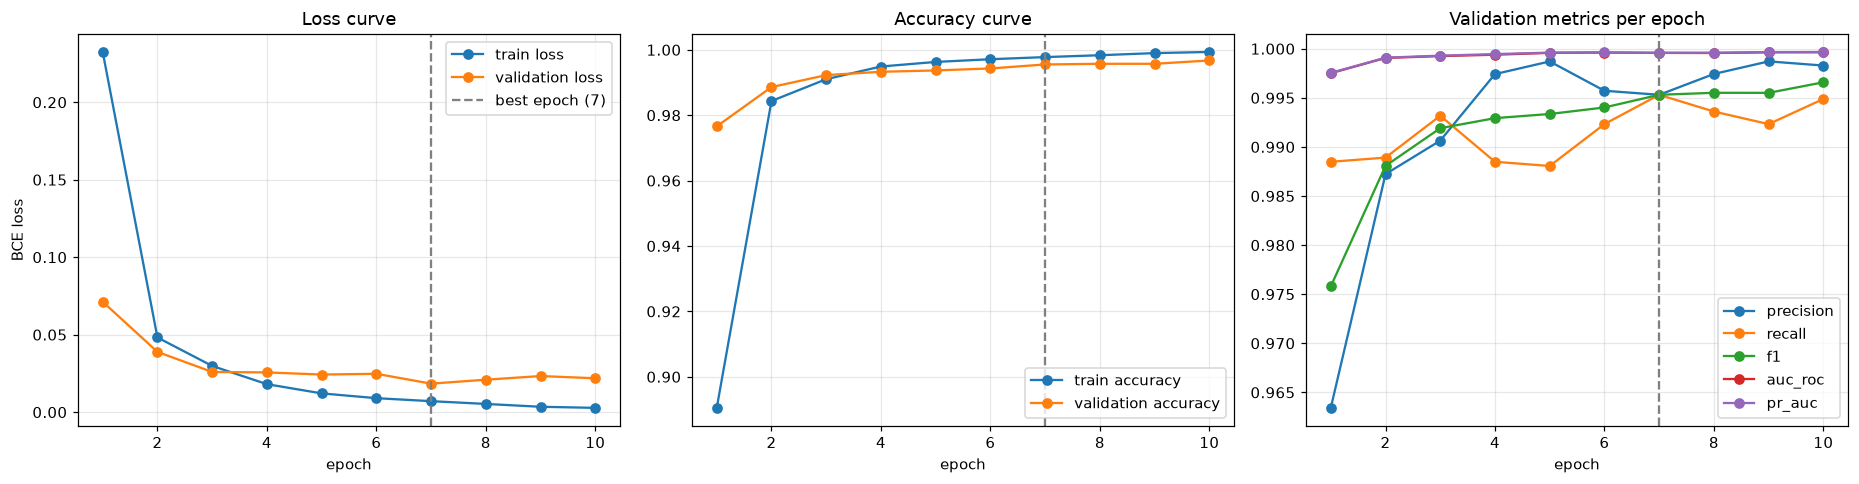

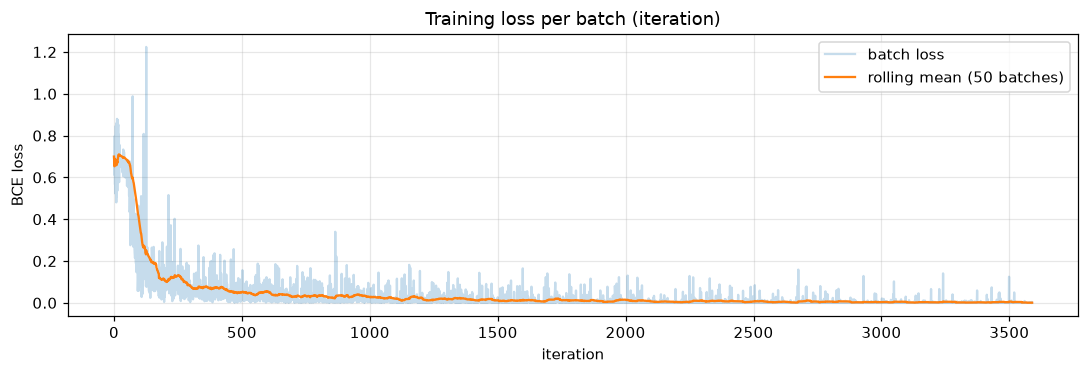

In [14]:
ep, best = metrics_log["epoch"], stopper.best_epoch
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(ep, metrics_log.train_loss, "o-", label="train loss")
axes[0].plot(ep, metrics_log.val_loss, "o-", label="validation loss")
axes[0].axvline(best, ls="--", c="grey", label=f"best epoch ({best})")
axes[0].set_title("Loss curve"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend()

axes[1].plot(ep, metrics_log.train_accuracy, "o-", label="train accuracy")
axes[1].plot(ep, metrics_log.val_accuracy, "o-", label="validation accuracy")
axes[1].axvline(best, ls="--", c="grey")
axes[1].set_title("Accuracy curve"); axes[1].set_xlabel("epoch"); axes[1].legend()

for m in ["precision", "recall", "f1", "auc_roc", "pr_auc"]:
    axes[2].plot(ep, metrics_log[f"val_{m}"], "o-", label=m)
axes[2].axvline(best, ls="--", c="grey")
axes[2].set_title("Validation metrics per epoch"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.tight_layout(); savefig("training_curves"); plt.show()

plt.figure(figsize=(10, 3.5))
s = pd.Series(batch_losses)
plt.plot(s, alpha=0.25, label="batch loss")
plt.plot(s.rolling(50, min_periods=1).mean(), label="rolling mean (50 batches)")
plt.title("Training loss per batch (iteration)"); plt.xlabel("iteration"); plt.ylabel("BCE loss"); plt.legend()
plt.tight_layout(); savefig("batch_loss"); plt.show()

### 10.2 Final evaluation on the held-out test set

The decision threshold is chosen on the **validation** set to maximise F1, then applied unchanged to the test set. The test set plays no part in any decision.

In [15]:
val_prob = predict(model, X_val)
THRESHOLD = best_f1_threshold(y_val, val_prob)
test_prob = predict(model, X_test)

results = pd.DataFrame({
    "TF-IDF + LogReg (baseline)": compute_metrics(test_df.label, base_test_prob, BASE_THRESHOLD),
    "BiLSTM @ 0.5": compute_metrics(y_test, test_prob, 0.5),
    f"BiLSTM @ tuned {THRESHOLD:.3f}": compute_metrics(y_test, test_prob, THRESHOLD),
}).T
results.to_csv(RESULTS_DIR / "test_metrics.csv")
display(results.style.format("{:.4f}").highlight_max(color="#c8e6c9").set_caption("Test-set results"))

,accuracy,precision,recall,f1,auc_roc,pr_auc
TF-IDF + LogReg (baseline),0.9963,0.9957,0.9966,0.9962,0.9999,0.9999
BiLSTM @ 0.5,0.9939,0.9923,0.9949,0.9936,0.9998,0.9998
BiLSTM @ tuned 0.873,0.9941,0.9953,0.9923,0.9938,0.9998,0.9998


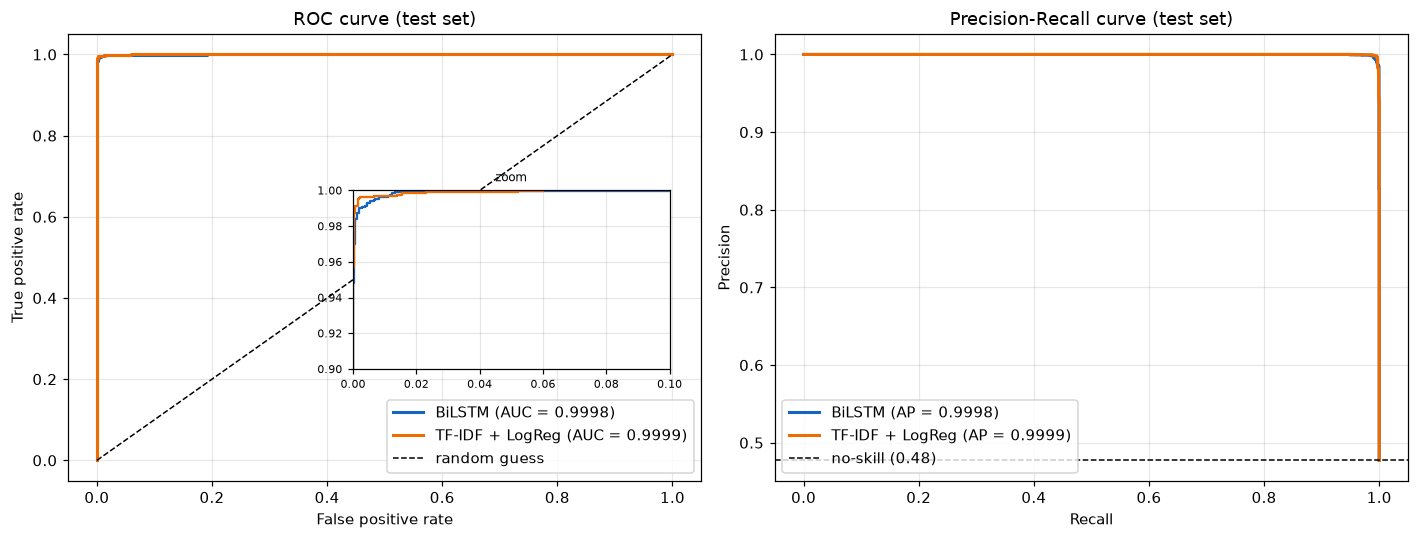

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob, col in [("BiLSTM", test_prob, "#1565c0"), ("TF-IDF + LogReg", base_test_prob, "#ef6c00")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, lw=2, c=col, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.4f})")
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(r, p, lw=2, c=col, label=f"{name} (AP = {average_precision_score(y_test, prob):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), c="k", ls="--", lw=1, label=f"no-skill ({y_test.mean():.2f})")
axes[1].set(title="Precision-Recall curve (test set)", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "lower left")

# zoomed inset so the near-perfect top-left corner of the ROC is readable
ins = axes[0].inset_axes([0.45, 0.25, 0.5, 0.4])
for prob, col in [(test_prob, "#1565c0"), (base_test_prob, "#ef6c00")]:
    fpr, tpr, _ = roc_curve(y_test, prob); ins.plot(fpr, tpr, c=col)
ins.set_xlim(0, 0.1); ins.set_ylim(0.9, 1.0); ins.set_title("zoom", fontsize=8); ins.tick_params(labelsize=7)
plt.tight_layout(); savefig("roc_pr_curves"); plt.show()

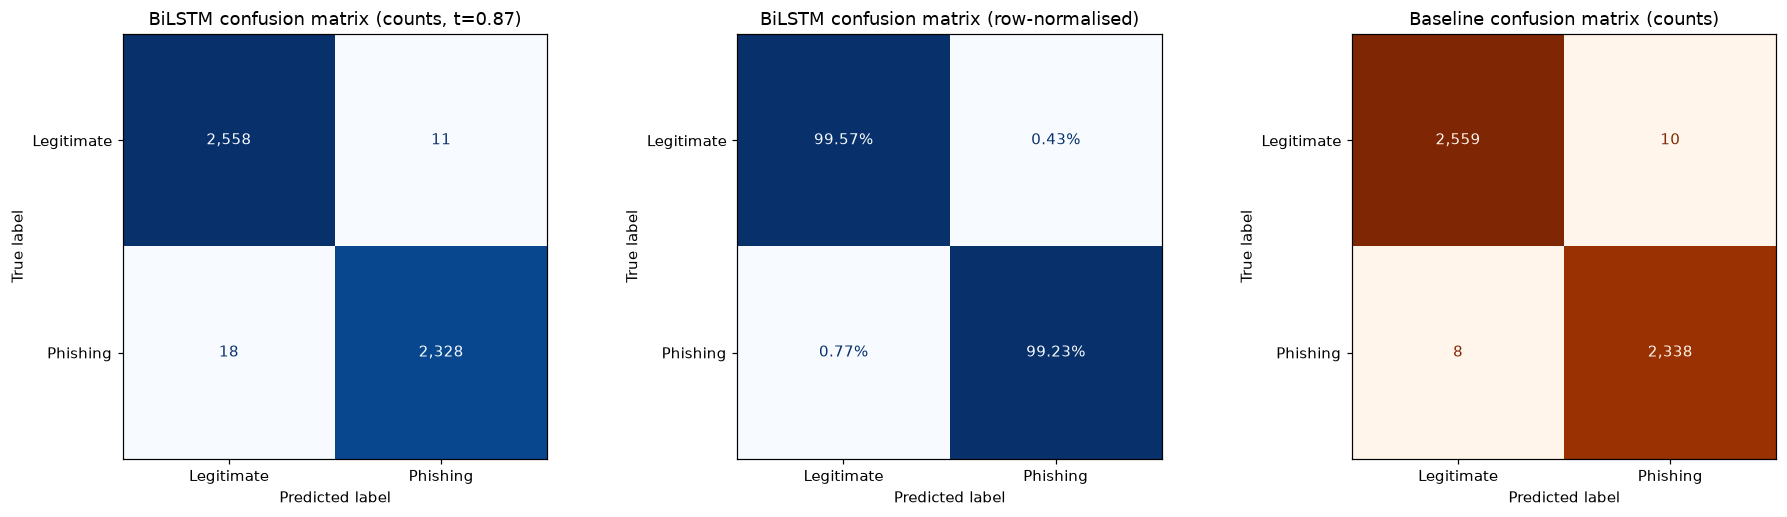

BiLSTM test: TP=2,328  TN=2,558  FP=11 (legit flagged)  FN=18 (phishing missed)
False positive rate = 0.43% | False negative rate = 0.77%


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
labels = ["Legitimate", "Phishing"]
cm = confusion_matrix(y_test, (test_prob >= THRESHOLD).astype(int))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title(f"BiLSTM confusion matrix (counts, t={THRESHOLD:.2f})")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=labels).plot(
    ax=axes[1], cmap="Blues", values_format=".2%", colorbar=False)
axes[1].set_title("BiLSTM confusion matrix (row-normalised)")
cm_b = confusion_matrix(test_df.label, (base_test_prob >= BASE_THRESHOLD).astype(int))
ConfusionMatrixDisplay(cm_b, display_labels=labels).plot(ax=axes[2], cmap="Oranges", values_format=",d", colorbar=False)
axes[2].set_title("Baseline confusion matrix (counts)")
for ax in axes: ax.grid(False)
plt.tight_layout(); savefig("confusion_matrices"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"BiLSTM test: TP={tp:,}  TN={tn:,}  FP={fp:,} (legit flagged)  FN={fn:,} (phishing missed)")
print(f"False positive rate = {fp/(fp+tn):.2%} | False negative rate = {fn/(fn+tp):.2%}")

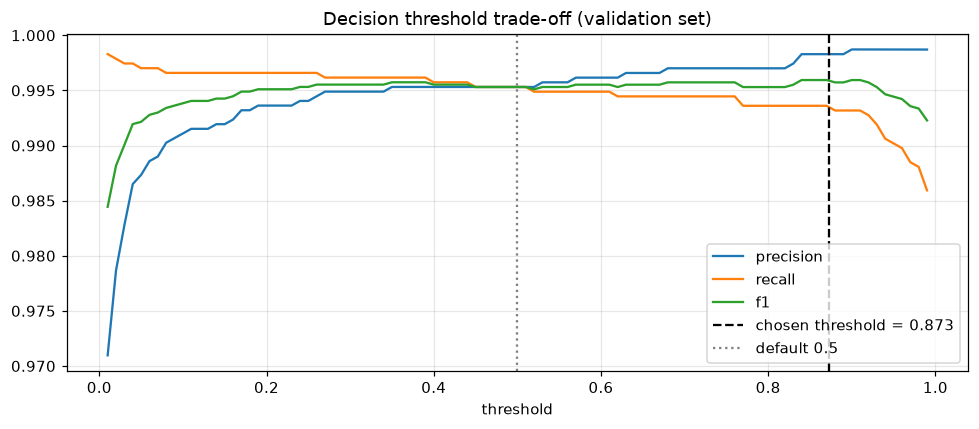

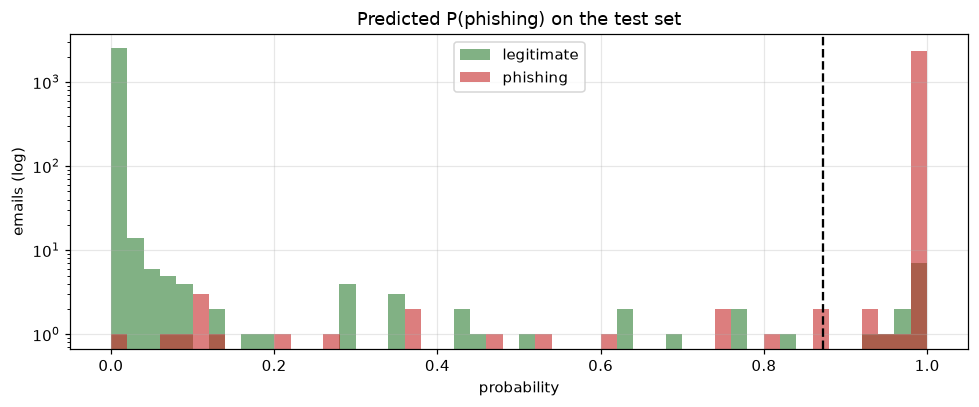

In [18]:
# Threshold trade-off: how precision / recall / F1 change as the cut-off moves (validation set)
ts = np.linspace(0.01, 0.99, 99)
curves = pd.DataFrame([{"t": t, **{k: v for k, v in compute_metrics(y_val, val_prob, t).items()
                                   if k in ("precision", "recall", "f1")}} for t in ts])
plt.figure(figsize=(9, 4))
for m in ["precision", "recall", "f1"]:
    plt.plot(curves.t, curves[m], label=m)
plt.axvline(THRESHOLD, c="k", ls="--", label=f"chosen threshold = {THRESHOLD:.3f}")
plt.axvline(0.5, c="grey", ls=":", label="default 0.5")
plt.title("Decision threshold trade-off (validation set)"); plt.xlabel("threshold"); plt.legend()
plt.tight_layout(); savefig("threshold_tradeoff"); plt.show()

plt.figure(figsize=(9, 3.8))
plt.hist(test_prob[y_test == 0], bins=50, alpha=0.6, color="#2e7d32", label="legitimate")
plt.hist(test_prob[y_test == 1], bins=50, alpha=0.6, color="#c62828", label="phishing")
plt.axvline(THRESHOLD, c="k", ls="--"); plt.yscale("log")
plt.title("Predicted P(phishing) on the test set"); plt.xlabel("probability"); plt.ylabel("emails (log)")
plt.legend(); plt.tight_layout(); savefig("probability_distribution"); plt.show()

## 11. Save the model for the API and desktop app

Saved to `models/`:
* `bilstm.pt`: the weights
* `vocab.json`: the vocabulary
* `config.json`: hyper-parameters, tuned thresholds and test metrics
* `baseline_tfidf_logreg.joblib`: the baseline model

The saved files are then reloaded through `PhishingDetector`, the same class the API uses, to confirm they produce identical predictions.

In [19]:
torch.save(model.state_dict(), MODEL_DIR / "bilstm.pt")
vocab.save(MODEL_DIR / "vocab.json")
saved_config = {
    "max_len": CONFIG["max_len"], "model_params": CONFIG["model_params"],
    "threshold": THRESHOLD, "baseline_threshold": BASE_THRESHOLD,
    "best_epoch": int(stopper.best_epoch), "epochs_run": int(len(metrics_log)),
    "trained_on": sorted(raw["source"].unique().tolist()),
    "train_size": len(train_df), "val_size": len(val_df), "test_size": len(test_df),
    "test_metrics": {k: round(float(v), 4) for k, v in compute_metrics(y_test, test_prob, THRESHOLD).items()},
    "trained_at": time.strftime("%Y-%m-%d %H:%M"),
}
(MODEL_DIR / "config.json").write_text(json.dumps(saved_config, indent=2))

detector = PhishingDetector(MODEL_DIR)
reloaded = detector.predict_proba(test_df.text.tolist()[:500])
assert np.allclose(reloaded, test_prob[:500], atol=1e-5), "saved model gives different predictions!"
print("Saved model reloads correctly:", [p.name for p in sorted(MODEL_DIR.iterdir())])
print(json.dumps(saved_config, indent=2))

Saved model reloads correctly: ['baseline_tfidf_logreg.joblib', 'bilstm.pt', 'config.json', 'vocab.json']
{
  "max_len": 256,
  "model_params": {
    "emb_dim": 100,
    "hidden_dim": 64,
    "num_layers": 1,
    "dropout": 0.3
  },
  "threshold": 0.8729077577590942,
  "baseline_threshold": 0.4618495633505291,
  "best_epoch": 7,
  "epochs_run": 10,
  "trained_on": [
    "CEAS_08"
  ],
  "train_size": 22933,
  "val_size": 4914,
  "test_size": 4915,
  "test_metrics": {
    "accuracy": 0.9941,
    "precision": 0.9953,
    "recall": 0.9923,
    "f1": 0.9938,
    "auc_roc": 0.9998,
    "pr_auc": 0.9998
  },
  "trained_at": "2026-10-18 05:03"
}


## 12. Error analysis

Here we look at the emails the model got **wrong**, with the most confident mistakes first. These cases show the model's limits and feed into the theory discussion (Section 3.3).

In [20]:
err = test_df.assign(prob=test_prob, pred=(test_prob >= THRESHOLD).astype(int))
show = lambda d: d[["subject", "prob"]].assign(body_start=d["body"].astype(str).str[:150].str.replace(r"\s+", " ", regex=True))
fp_df = err[(err.pred == 1) & (err.label == 0)].sort_values("prob", ascending=False)
fn_df = err[(err.pred == 0) & (err.label == 1)].sort_values("prob")
print(f"False positives (legitimate flagged as phishing): {len(fp_df)}")
display(show(fp_df.head(8)))
print(f"False negatives (phishing that got through): {len(fn_df)}")
display(show(fn_df.head(8)))

False positives (legitimate flagged as phishing): 11


,subject,prob,body_start
1139,APEC security,0.999729,http://www.youtube.com/results?search_query=chasers+%2B+apec&search=Search
4241,[ILUG] Hello!,0.999129,"Hi, Here is two finnish penquins seeking for friends in Dublin. If you wanna meet couple of finns suggest a time and..."
2941,Welcome To Ustream.tv!,0.997317,Thank you for signing up with Ustream.tv Here is your username and password information. Please keep this informati...
4268,still waiting?,0.995024,"Hello, I am still waiting on your answser..is it OK if buy your script, for me to implement inside it Openads part o..."
4157,Over 250 Items On Sale at Alpenland International Online!,0.994673,"Huge Sale at Alpenland International! If you wish to be removed from our mailing list, please send an email to pbbh..."
1194,[ILUG] AGM Today...,0.985697,Don't forget today's ILUG Annnual General Meeting - 3pm in the ICS building. ( http://www.ics.ie/main/contact.htm )...
1466,CNN Alerts: bush,0.979780,"CNN Alerts: bush Alert Name: bush Nation's bridges, roads still 'structurally deficient' 08/01/08 11:55 AM, EDT Mer..."
2847,[Dixielandjazz] A Jazz Chordl,0.973181,Stevie Wonder is playing his first gig in Tokyo and the place is absolutely packed to the rafters. In a bid to brea...


False negatives (phishing that got through): 18


,subject,prob,body_start
3538,"Considered UNSOLICITED BULK EMAIL, apparently from you",0.000228,A message from to: -> golden@imot.bg was considered unsolicited bulk e-mail (UBE). Our internal reference code for y...
3881,Scientists prove landing in Mars staged,0.066287,"All the dirty secrets about American Idol, you win by getting there with favors. http://opticastock.com/news.html No..."
1978,A new and exciting look at luxury watches,0.084050,http://www.leadcurve.com/ You have been put into the hate list by IT department
2607,Payment confirmation #2711018404799517757,0.101907,This email is for informational purposes only. Do not reply to the email address above. A payment to Carrington Mort...
546,Old photos,0.105914,ArIToRw Secure Mail System Beta Test.
1043,Database of cardiologists and dozens more specialties,0.112175,"Currently in Practice: Physicians in the USA 788,399 in total <> 17,707 emails Many popular specialties like Emergen..."
4182,ATTENTION! PLEASE GO THROUGH YOUR MESSAGE (VERY URGENT),0.138519,POWER BALL ORGANIZATION 203 Canary Wharf London E12 4LN File number: 022-046-100168 Batch number: 30/0117/SPB08
1465,You can increase the time of your sexual act,0.203764,"I've played on and off with pumps, weights, and exercises for the last few years and have never gained one centimet..."


## 13. Explainable AI (bonus, rubric 2.7)

Three complementary explanations:
1. **Global (baseline):** the logistic regression weights show which words push *any* email towards phishing or legitimate.
2. **Local, occlusion (BiLSTM):** remove each word from one specific email and measure how much the model's **log-odds** of phishing drop. Log-odds are used because a probability of 0.9999 barely changes when one word is removed. The desktop app uses this method to highlight words.
3. **Local, LIME (BiLSTM):** LIME fits a simple surrogate model around one email to explain the BiLSTM's decision for it (Ribeiro et al., 2016).

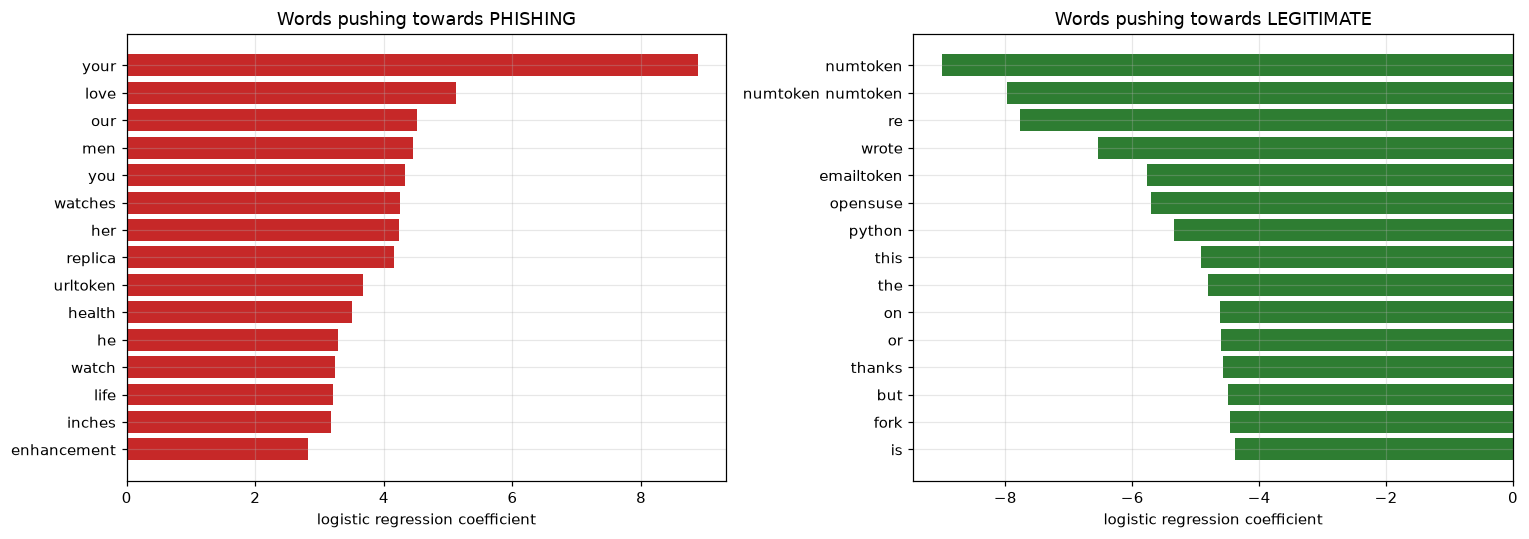

In [21]:
names = baseline.named_steps["tfidf"].get_feature_names_out()
coefs = baseline.named_steps["clf"].coef_[0]
top_pos, top_neg = np.argsort(coefs)[-15:], np.argsort(coefs)[:15]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(names[top_pos], coefs[top_pos], color="#c62828"); axes[0].set_title("Words pushing towards PHISHING")
axes[1].barh(names[top_neg][::-1], coefs[top_neg][::-1], color="#2e7d32"); axes[1].set_title("Words pushing towards LEGITIMATE")
for ax in axes: ax.set_xlabel("logistic regression coefficient")
plt.tight_layout(); savefig("xai_global_logreg"); plt.show()

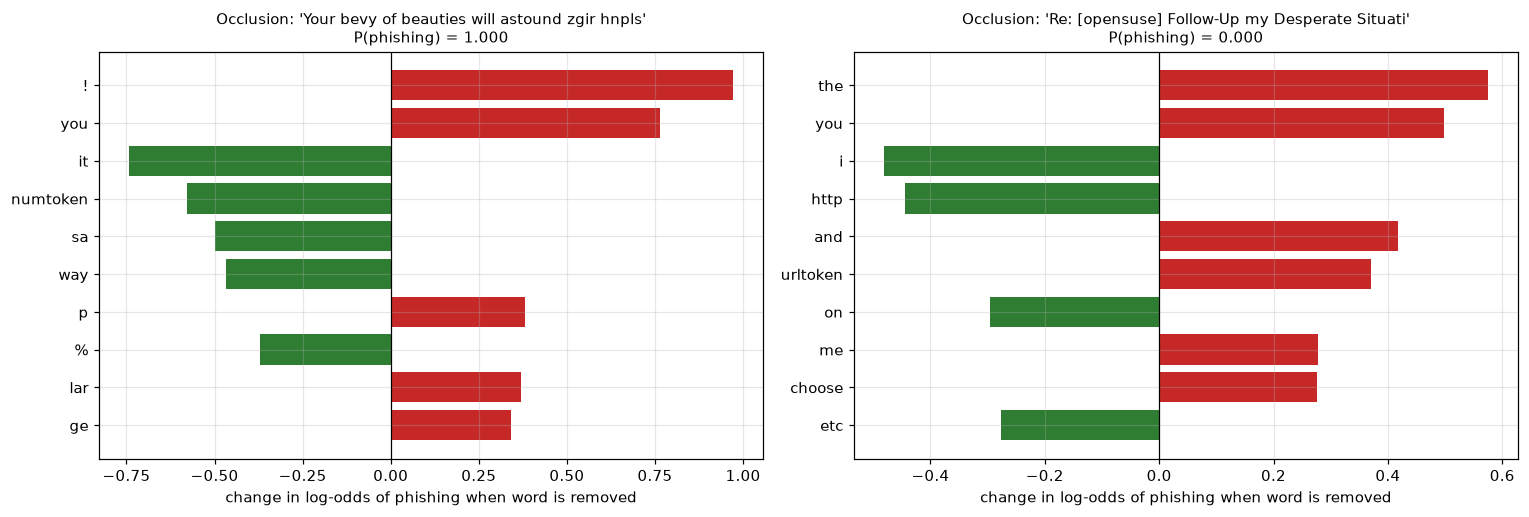

In [22]:
def plot_explanation(expl, title, ax):
    toks = [e["token"] for e in expl][::-1]; w = [e["weight"] for e in expl][::-1]
    ax.barh(toks, w, color=["#c62828" if v > 0 else "#2e7d32" for v in w])
    ax.axvline(0, c="k", lw=0.8); ax.set_title(title, fontsize=10)
    ax.set_xlabel("change in log-odds of phishing when word is removed")

ph_ex = test_df[(test_df.label == 1) & (test_prob > 0.95)].iloc[0]
lg_ex = test_df[(test_df.label == 0) & (test_prob < 0.05)].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, ex in zip(axes, [ph_ex, lg_ex]):
    r = detector.analyse(ex.subject, ex.body)
    plot_explanation(r["top_tokens"], f"Occlusion: '{str(ex.subject)[:45]}'\nP(phishing) = {r['probability']:.3f}", ax)
plt.tight_layout(); savefig("xai_occlusion"); plt.show()

In [23]:
try:
    from lime.lime_text import LimeTextExplainer
    explainer = LimeTextExplainer(class_names=["legitimate", "phishing"], random_state=SEED)
    lime_fn = lambda texts: np.column_stack([1 - detector.predict_proba(list(texts)),
                                             detector.predict_proba(list(texts))])
    for ex in [ph_ex, lg_ex]:
        exp = explainer.explain_instance(ex.text, lime_fn, num_features=10, num_samples=1000)
        fig = exp.as_pyplot_figure(label=1)
        fig.set_size_inches(8, 4)
        plt.title(f"LIME: '{str(ex.subject)[:50]}' (label = {ex.label})", fontsize=10)
        plt.tight_layout(); plt.show()
except ImportError:
    print("LIME is not installed. Run `pip install lime` to see LIME explanations (occlusion results above still apply).")

LIME is not installed. Run `pip install lime` to see LIME explanations (occlusion results above still apply).


## 14. Sanity check on hand-written emails

These emails were written for this test and are **not** from the dataset. The "PayPal" example is a classic credential-phishing email. CEAS_08's positive class is mostly *spam* (pharmacy ads, replica watches) rather than credential theft, so this check shows whether the model generalises to real phishing.

,subject,BiLSTM P(phish),BiLSTM,baseline P(phish),baseline,top BiLSTM words
0,Your PayPal account has been limited,0.1197,legitimate,0.8921,phishing,"your, hours"
1,URGENT: Your mailbox is full,0.9962,phishing,0.8828,phishing,"!, your"
2,Cheap replica watches - 80% off,1.0000,phishing,0.9957,phishing,"watches, replica, !, buy"
3,Re: group project meeting on Thursday,0.0083,legitimate,0.0471,legitimate,"meeting, github"
4,Re: [Python-Dev] patch review for issue 2291,0.0000,legitimate,0.0174,legitimate,?


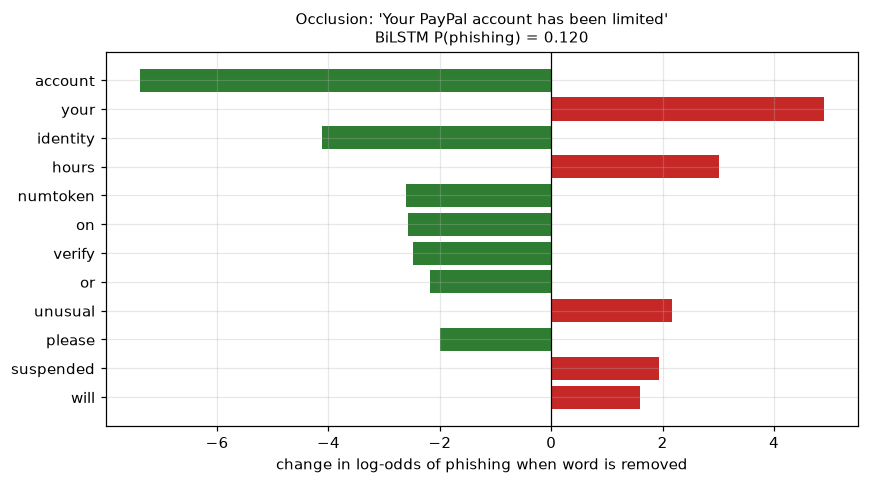

In [24]:
samples = [
    ("Your PayPal account has been limited",
     "Dear customer, we noticed unusual activity on your account. Please verify your identity within 24 hours "
     "or your account will be suspended. Click here: http://paypal-secure-verify.com/login and enter your password."),
    ("URGENT: Your mailbox is full",
     "Your email quota has exceeded the limit. Click http://webmail-upgrade.net to upgrade now or lose all messages!!!"),
    ("Cheap replica watches - 80% off",
     "Buy luxury replica watches at the lowest prices! Rolex, Omega and more. Visit www.best-replicas.biz today!"),
    ("Re: group project meeting on Thursday",
     "Hi Wayne, can we move the ITRI625 meeting to 14:00? I pushed the notebook changes to GitHub. Thanks, Asemahle"),
    ("Re: [Python-Dev] patch review for issue 2291",
     "I looked at the patch and the tests pass on Linux. Could someone check the Windows build before we merge?"),
]
rows = []
for subj, body in samples:
    r = detector.analyse(subj, body, top_k=5)
    b = detector.analyse(subj, body, model="baseline", top_k=5)
    rows.append({"subject": subj, "BiLSTM P(phish)": r["probability"], "BiLSTM": r["label"],
                 "baseline P(phish)": b["probability"], "baseline": b["label"],
                 "top BiLSTM words": ", ".join(t["token"] for t in r["top_tokens"] if t["weight"] > 0)})
display(pd.DataFrame(rows))

# Why did the BiLSTM decide what it did on the credential-phishing example?
fig, ax = plt.subplots(figsize=(8, 4.5))
r = detector.analyse(*samples[0], top_k=12)
plot_explanation(r["top_tokens"], f"Occlusion: '{samples[0][0]}'\nBiLSTM P(phishing) = {r['probability']:.3f}", ax)
plt.tight_layout(); savefig("xai_handwritten_phishing"); plt.show()

**How to read this.** If the PayPal-style email comes back as *legitimate* from the BiLSTM, that is the dataset limitation showing up. In CEAS_08 the malicious class is mostly 2008-era **spam**: pharmacy, replica watches, adult content. Words like *account*, *verify* and *password* appear more often in its **legitimate** emails, which are largely IT mailing lists. The occlusion chart above shows which words pulled the decision either way.

This is a strong point for theory sections 3.3 and 3.4: a model can score above 99% on its own test set and still miss a modern credential-phishing email, because the training data is old and covers a different kind of threat (**dataset shift / concept drift**). The fix is to add a real phishing corpus, e.g. `Nazario.csv`, to `data/` and re-run the notebook.

## 15. Summary

* The cell below prints the final numbers. The figures are also saved in `results/figures/`, and the per-epoch log in `results/metrics_log.csv`.
* The model is saved in `models/`. Start the API with `uvicorn api.main:app --reload` from the project root, then run `python app/desktop_app.py`.
* **Points for the theory report (3.3 / 3.4):**
  * Removing duplicates before splitting matters: a large share of the raw corpus was duplicated.
  * Test scores on CEAS_08 are very high, partly because 2008 spam is very formulaic. Real-world performance on modern phishing would be lower: dataset age and **concept drift** are the main limitation.
  * The positive class in CEAS_08 is mostly spam. Adding the **Nazario** phishing corpus is the recommended next step, so the model learns credential-theft patterns (see Section 14).
  * Trade-off between false positives and false negatives: the threshold can be moved (see the threshold plot), depending on whether missed phishing or blocked legitimate mail is more costly.

In [25]:
print("Best epoch:", stopper.best_epoch, "of", len(metrics_log), "| threshold:", round(THRESHOLD, 3))
display(results.style.format("{:.4f}"))

Best epoch: 7 of 10 | threshold: 0.873


,accuracy,precision,recall,f1,auc_roc,pr_auc
TF-IDF + LogReg (baseline),0.9963,0.9957,0.9966,0.9962,0.9999,0.9999
BiLSTM @ 0.5,0.9939,0.9923,0.9949,0.9936,0.9998,0.9998
BiLSTM @ tuned 0.873,0.9941,0.9953,0.9923,0.9938,0.9998,0.9998
